#**Installing required libraries**

In [1]:
import os
import re
import gc
import json
import random
import shutil
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    silhouette_score,
    adjusted_rand_score
)
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA

from sentence_transformers import SentenceTransformer
import joblib

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

PyTorch: 2.11.0+cu128
CUDA available: True
Device: cuda


#**Experiment configuration**

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# -------------------------------
# Dataset / experiment settings
# -------------------------------

ZIP_NAME = "/content/Wine_Dataset.zip"
EXTRACT_DIR = "/content/wine_data"
OUTPUT_DIR = "/content/wine_project_results"

# Class selection
N_KNOWN_CLASSES = 100
N_HELDOUT_CLASSES = 20

# Sampling
MIN_RECORDS_PER_CLASS = 30
MAX_RECORDS_PER_CLASS = 200

# External unknown records
MAX_EXTERNAL_UNKNOWN = 5000

# BERT
BERT_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
BERT_BATCH_SIZE = 128

# Clustering
N_CLUSTERS = 20
MAX_CLUSTER_RECORDS = 5000

# OSR threshold percentile
OSR_PERCENTILE = 5

# Create output folders
for folder in [
    OUTPUT_DIR,
    f"{OUTPUT_DIR}/figures",
    f"{OUTPUT_DIR}/models",
    f"{OUTPUT_DIR}/results",
    f"{OUTPUT_DIR}/processed_data"
]:
    os.makedirs(folder, exist_ok=True)

CONFIG = {
    "seed": SEED,
    "known_classes": N_KNOWN_CLASSES,
    "heldout_classes": N_HELDOUT_CLASSES,
    "minimum_records_per_class": MIN_RECORDS_PER_CLASS,
    "maximum_records_per_class": MAX_RECORDS_PER_CLASS,
    "maximum_external_unknown": MAX_EXTERNAL_UNKNOWN,
    "bert_model": BERT_MODEL_NAME,
    "bert_batch_size": BERT_BATCH_SIZE,
    "requested_clusters": N_CLUSTERS,
    "osr_percentile": OSR_PERCENTILE
}

with open(f"{OUTPUT_DIR}/experiment_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

print(json.dumps(CONFIG, indent=2))

{
  "seed": 42,
  "known_classes": 100,
  "heldout_classes": 20,
  "minimum_records_per_class": 30,
  "maximum_records_per_class": 200,
  "maximum_external_unknown": 5000,
  "bert_model": "sentence-transformers/all-MiniLM-L6-v2",
  "bert_batch_size": 128,
  "requested_clusters": 20,
  "osr_percentile": 5
}


#**DATA LOADING AND PREPARATION**

In [3]:
from google.colab import files

if not os.path.exists(ZIP_NAME):
    print("Please upload Wine_Dataset.zip")
    uploaded = files.upload()

if not os.path.exists(ZIP_NAME):
    raise FileNotFoundError(
        "Wine_Dataset.zip was not found. "
        "Please upload the file with exactly this name."
    )

print("Dataset ZIP found:")
print(ZIP_NAME)
print("Size:", round(os.path.getsize(ZIP_NAME) / (1024**2), 2), "MB")

Please upload Wine_Dataset.zip


Saving Wine_Dataset.zip to Wine_Dataset.zip
Dataset ZIP found:
/content/Wine_Dataset.zip
Size: 45.91 MB


#**Extract ZIP and identify CSV files**

In [4]:
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, "r") as z:
    z.extractall(EXTRACT_DIR)

csv_files = list(Path(EXTRACT_DIR).rglob("*.csv"))

print("CSV files found:")
for file in csv_files:
    print(" -", file)

if len(csv_files) == 0:
    raise ValueError("No CSV files found inside Wine_Dataset.zip")


matched_file = None
unknown_file = None

for file in csv_files:
    name = file.name.lower()

    if "matched" in name:
        matched_file = str(file)

    if "unknown" in name:
        unknown_file = str(file)

print("\nMatched dataset:", matched_file)
print("Unknown dataset:", unknown_file)

if matched_file is None:
    raise FileNotFoundError(
        "Could not automatically identify matched_wines.csv"
    )

CSV files found:
 - /content/wine_data/filtered_unknown.csv
 - /content/wine_data/matched_wines.csv

Matched dataset: /content/wine_data/matched_wines.csv
Unknown dataset: /content/wine_data/filtered_unknown.csv


#**Loading datasets**

In [5]:
matched_df = pd.read_csv(
    matched_file,
    low_memory=False
)

print("Matched wines shape:", matched_df.shape)
print("\nMatched columns:")
print(matched_df.columns.tolist())

display(matched_df.head())


if unknown_file is not None:
    unknown_df = pd.read_csv(
        unknown_file,
        low_memory=False
    )

    print("\nUnknown dataset shape:", unknown_df.shape)
    print("Unknown columns:")
    print(unknown_df.columns.tolist())

    display(unknown_df.head())

else:
    unknown_df = None
    print("\nSeparate unknown dataset not found.")

Matched wines shape: (500000, 3)

Matched columns:
['originalname', 'standardname', 'winekey']


,originalname,standardname,winekey
0,Secuencias Viognier Uco Valley [2448459] Reserve,Premium SECUENCIAS VIOGNIER UCO VALLEY,884236.0
1,Norton Vinho Branco - Porteno Sauvignon Blanc ...,NORTON BLANCO PORTENO SAUV BLANC ARGENTINA MEN...,637855.0
2,Casa Miriam Reserve Cabernet Sauvignon Mendoza...,CASA MIRIAM RSRV CAB SAUV MENDOZA RED ARGENTINA,215224.0
3,2010 Tacuil Vinas de Davalos Salta Argentina,TACUIL VINAS DE DAVALOS SALTA ARGENTINA,165938.0
4,Vistandes Torrontes Reserve (Special Edition),VISTANDES TORRONT RSRV (Premium),60296.0



Unknown dataset shape: (2050085, 4)
Unknown columns:
['winekey', 'origin_name', 'std_name', 'country']


,winekey,origin_name,std_name,country
0,893,"2002, Scarpantoni Estate Wines, McLaren Vale U...",SCARPANTONI ESTATE MC LAREN VALE UNOAKED CHARD,Australia
1,893,2003 Scarpantoni Estates Chardonnay Unwooded M...,SCARPANTONI ESTATE CHARD UNOAKED MC LAREN VALE,Australia
2,893,"2003, Scarpantoni Estate Wines, McLaren Vale U...",SCARPANTONI ESTATE MC LAREN VALE UNOAKED CHARD,Australia
3,893,"2004, Scarpantoni Estate Wines, McLaren Vale U...",SCARPANTONI ESTATE MC LAREN VALE UNOAKED CHARD,Australia
4,893,"2004, Scarpantoni, McLaren Vale Unwooded Chard...",SCARPANTONI MC LAREN VALE UNOAKED CHARD,Australia


#**Standardize column names and inspect data**

In [6]:
def standardize_columns(df):
    df = df.copy()

    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

    return df


matched_df = standardize_columns(matched_df)

if unknown_df is not None:
    unknown_df = standardize_columns(unknown_df)


print("Matched columns:")
print(matched_df.columns.tolist())

if unknown_df is not None:
    print("\nUnknown columns:")
    print(unknown_df.columns.tolist())


print("\nMatched dataset information:")
print("Rows:", len(matched_df))
print("Columns:", len(matched_df.columns))

print("\nMissing values:")
display(
    matched_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Matched columns:
['originalname', 'standardname', 'winekey']

Unknown columns:
['winekey', 'origin_name', 'std_name', 'country']

Matched dataset information:
Rows: 500000
Columns: 3

Missing values:


,0
originalname,0
standardname,0
winekey,0


#**Identifing text and target columns automatically**

In [7]:
def find_column(columns, candidates):

    for candidate in candidates:
        if candidate in columns:
            return candidate

    return None


TARGET_COL = find_column(
    matched_df.columns,
    ["winekey", "wine_key", "wineid", "wine_id"]
)

ORIGINAL_COL = find_column(
    matched_df.columns,
    [
        "originalname",
        "original_name",
        "origin_name",
        "wine_name",
        "name"
    ]
)

STANDARD_COL = find_column(
    matched_df.columns,
    [
        "standardname",
        "standard_name",
        "std_name"
    ]
)


print("Target column:", TARGET_COL)
print("Original text column:", ORIGINAL_COL)
print("Standard text column:", STANDARD_COL)


if TARGET_COL is None:
    raise ValueError("Wine Key column could not be identified.")

if ORIGINAL_COL is None and STANDARD_COL is None:
    raise ValueError("No suitable wine text column found.")

Target column: winekey
Original text column: originalname
Standard text column: standardname


#**Clean and construct BERT text**

In [8]:
def clean_text(text):

    text = str(text).lower().strip()

    text = re.sub(r"\s+", " ", text)

    text = re.sub(
        r"[^a-z0-9À-ÿ\s\-'&/.]",
        " ",
        text
    )

    text = re.sub(r"\s+", " ", text)

    return text.strip()


# Remove missing target
matched_df = matched_df.dropna(
    subset=[TARGET_COL]
).copy()


# Construct semantic text
if ORIGINAL_COL and STANDARD_COL:

    matched_df["text"] = (
        matched_df[ORIGINAL_COL].fillna("").astype(str)
        + " "
        + matched_df[STANDARD_COL].fillna("").astype(str)
    )

elif ORIGINAL_COL:

    matched_df["text"] = (
        matched_df[ORIGINAL_COL]
        .fillna("")
        .astype(str)
    )

else:

    matched_df["text"] = (
        matched_df[STANDARD_COL]
        .fillna("")
        .astype(str)
    )


matched_df["text"] = (
    matched_df["text"]
    .apply(clean_text)
)


# Remove empty text
matched_df = matched_df[
    matched_df["text"].str.len() > 2
].copy()


# Remove exact duplicates
before = len(matched_df)

matched_df = matched_df.drop_duplicates(
    subset=["text", TARGET_COL]
).reset_index(drop=True)

after = len(matched_df)


print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", after)
print("Duplicates removed:", before - after)

print("Unique Wine Keys:", matched_df[TARGET_COL].nunique())

display(matched_df[["text", TARGET_COL]].head())

Rows before duplicate removal: 500000
Rows after duplicate removal: 482684
Duplicates removed: 17316
Unique Wine Keys: 12842


,text,winekey
0,secuencias viognier uco valley 2448459 reserve...,884236.0
1,norton vinho branco - porteno sauvignon blanc ...,637855.0
2,casa miriam reserve cabernet sauvignon mendoza...,215224.0
3,2010 tacuil vinas de davalos salta argentina t...,165938.0
4,vistandes torrontes reserve special edition vi...,60296.0


#**EDA + VISUALISATION**

##**Full dataset statistics**

In [9]:
class_counts = (
    matched_df[TARGET_COL]
    .value_counts()
)

matched_df["text_length"] = (
    matched_df["text"]
    .str.split()
    .str.len()
)


summary = {
    "total_clean_records": int(len(matched_df)),
    "unique_wine_keys": int(matched_df[TARGET_COL].nunique()),
    "average_text_words": float(
        matched_df["text_length"].mean()
    ),
    "median_text_words": float(
        matched_df["text_length"].median()
    ),
    "minimum_class_size": int(class_counts.min()),
    "maximum_class_size": int(class_counts.max())
}


print("FULL DATASET SUMMARY")

for key, value in summary.items():
    print(f"{key}: {value}")


pd.DataFrame(
    [summary]
).to_csv(
    f"{OUTPUT_DIR}/results/full_dataset_summary.csv",
    index=False
)

FULL DATASET SUMMARY
total_clean_records: 482684
unique_wine_keys: 12842
average_text_words: 15.092661037034581
median_text_words: 13.0
minimum_class_size: 27
maximum_class_size: 76


#**EDA visualizations**

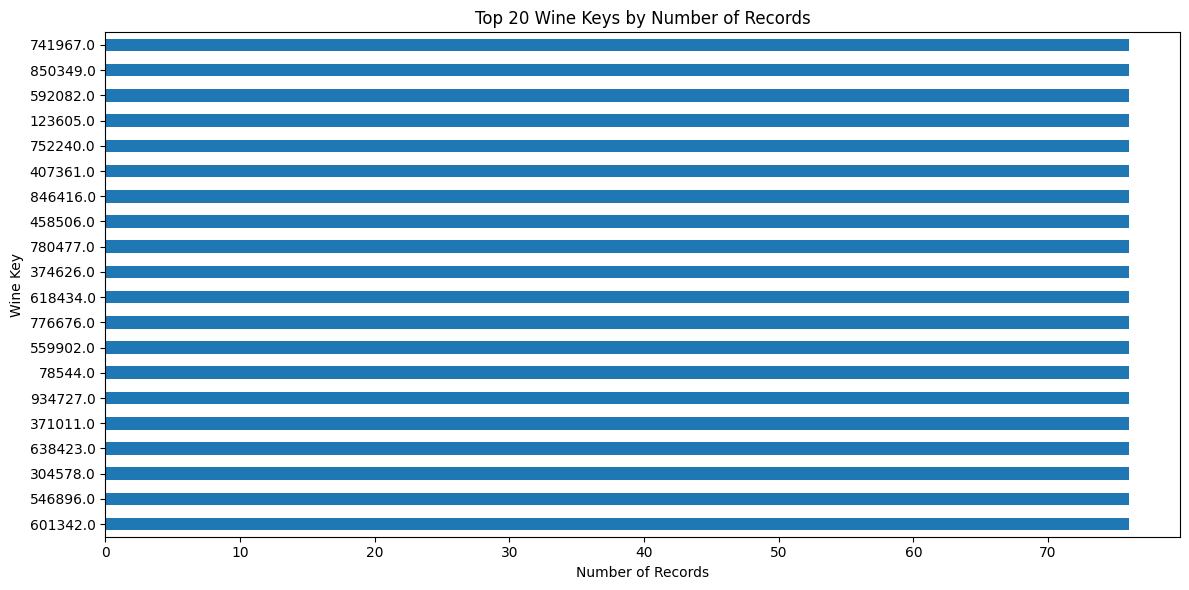

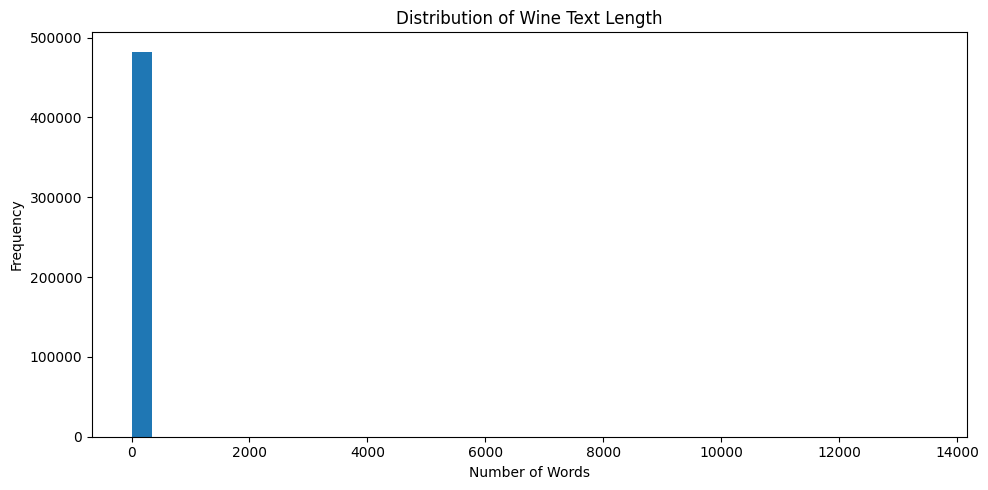

In [10]:
top_classes = class_counts.head(20)

plt.figure(figsize=(12, 6))

top_classes.sort_values().plot(
    kind="barh"
)

plt.title("Top 20 Wine Keys by Number of Records")
plt.xlabel("Number of Records")
plt.ylabel("Wine Key")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/top_wine_keys.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(10, 5))

plt.hist(
    matched_df["text_length"],
    bins=40
)

plt.title("Distribution of Wine Text Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/text_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#**CONTROLLED OPEN-SET EXPERIMENT**

##**Selecting eligible Wine Keys**

In [11]:
eligible_counts = class_counts[
    class_counts >= MIN_RECORDS_PER_CLASS
]

print("Eligible classes:", len(eligible_counts))


required_classes = (
    N_KNOWN_CLASSES +
    N_HELDOUT_CLASSES
)


if len(eligible_counts) < required_classes:

    raise ValueError(
        f"Only {len(eligible_counts)} classes contain at least "
        f"{MIN_RECORDS_PER_CLASS} records, but "
        f"{required_classes} are required."
    )


# Shuffle reproducibly
eligible_classes = (
    eligible_counts
    .sample(
        frac=1,
        random_state=SEED
    )
    .index
    .tolist()
)


known_classes = eligible_classes[
    :N_KNOWN_CLASSES
]

heldout_classes = eligible_classes[
    N_KNOWN_CLASSES:
    N_KNOWN_CLASSES + N_HELDOUT_CLASSES
]


print("Known Wine Keys:", len(known_classes))
print("Held-out Wine Keys:", len(heldout_classes))

print("\nExample known classes:")
print(known_classes[:10])

print("\nExample held-out classes:")
print(heldout_classes[:10])

Eligible classes: 12824
Known Wine Keys: 100
Held-out Wine Keys: 20

Example known classes:
[678435.0, 64490.0, 672010.0, 455838.0, 53596.0, 299314.0, 931563.0, 394754.0, 864290.0, 324510.0]

Example held-out classes:
[70772.0, 539320.0, 457299.0, 855678.0, 356837.0, 644704.0, 552089.0, 165766.0, 618428.0, 187715.0]


##**Balanced sampling and train/test construction**

In [12]:
def balanced_class_sample(
    df,
    classes,
    target_col,
    max_records,
    seed=42
):

    frames = []

    for cls in tqdm(classes):

        group = df[
            df[target_col] == cls
        ]

        n = min(
            len(group),
            max_records
        )

        sample = group.sample(
            n=n,
            random_state=seed
        )

        frames.append(sample)

    return pd.concat(
        frames,
        ignore_index=True
    )


known_df = balanced_class_sample(
    matched_df,
    known_classes,
    TARGET_COL,
    MAX_RECORDS_PER_CLASS,
    SEED
)


heldout_df = balanced_class_sample(
    matched_df,
    heldout_classes,
    TARGET_COL,
    MAX_RECORDS_PER_CLASS,
    SEED
)


train_df, known_test_df = train_test_split(
    known_df,
    test_size=0.20,
    random_state=SEED,
    stratify=known_df[TARGET_COL]
)


print("Training records:", len(train_df))
print("Known test records:", len(known_test_df))
print("Held-out unknown records:", len(heldout_df))

print(
    "Training classes:",
    train_df[TARGET_COL].nunique()
)

print(
    "Held-out classes:",
    heldout_df[TARGET_COL].nunique()
)


# Confirm no held-out class leakage
overlap = (
    set(train_df[TARGET_COL])
    &
    set(heldout_df[TARGET_COL])
)

print("\nClass leakage:", len(overlap))

assert len(overlap) == 0

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Training records: 3052
Known test records: 763
Held-out unknown records: 729
Training classes: 100
Held-out classes: 20

Class leakage: 0


#**BERT REPRESENTATION**

##**Load BERT embedding model**

In [13]:
print("Loading BERT model...")

bert_model = SentenceTransformer(
    BERT_MODEL_NAME,
    device=DEVICE
)

print("Loaded:", BERT_MODEL_NAME)

embedding_dimension = (
    bert_model.get_sentence_embedding_dimension()
)

print(
    "Embedding dimension:",
    embedding_dimension
)

Loading BERT model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384


#**Generate BERT embeddings**

In [14]:
def generate_embeddings(texts):

    return bert_model.encode(
        texts.tolist(),
        batch_size=BERT_BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )


print("Generating TRAIN embeddings")

X_train = generate_embeddings(
    train_df["text"]
)


print("\nGenerating KNOWN TEST embeddings")

X_known_test = generate_embeddings(
    known_test_df["text"]
)


print("\nGenerating HELD-OUT UNKNOWN embeddings")

X_heldout = generate_embeddings(
    heldout_df["text"]
)


print("\nShapes")

print("Train:", X_train.shape)
print("Known test:", X_known_test.shape)
print("Held-out:", X_heldout.shape)


np.save(
    f"{OUTPUT_DIR}/processed_data/train_embeddings.npy",
    X_train
)

np.save(
    f"{OUTPUT_DIR}/processed_data/known_test_embeddings.npy",
    X_known_test
)

np.save(
    f"{OUTPUT_DIR}/processed_data/heldout_embeddings.npy",
    X_heldout
)

Generating TRAIN embeddings


Batches:   0%|          | 0/24 [00:00<?, ?it/s]


Generating KNOWN TEST embeddings


Batches:   0%|          | 0/6 [00:00<?, ?it/s]


Generating HELD-OUT UNKNOWN embeddings


Batches:   0%|          | 0/6 [00:00<?, ?it/s]


Shapes
Train: (3052, 384)
Known test: (763, 384)
Held-out: (729, 384)


#**KNOWN WINE CLASSIFICATION**

##**Encode Wine Keys and train classifier**

In [15]:
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    train_df[TARGET_COL]
)

y_known_test = label_encoder.transform(
    known_test_df[TARGET_COL]
)


classifier = LogisticRegression(
    max_iter=1500,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)


print("Training classifier...")

classifier.fit(
    X_train,
    y_train
)

print("Training complete.")


joblib.dump(
    classifier,
    f"{OUTPUT_DIR}/models/wine_classifier.pkl"
)

joblib.dump(
    label_encoder,
    f"{OUTPUT_DIR}/models/label_encoder.pkl"
)

print("Models saved.")

Training classifier...
Training complete.
Models saved.


##**Evaluate known wine classification**

In [16]:
known_predictions = classifier.predict(
    X_known_test
)

known_probabilities = classifier.predict_proba(
    X_known_test
)


accuracy = accuracy_score(
    y_known_test,
    known_predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_known_test,
        known_predictions,
        average="weighted",
        zero_division=0
    )
)


classification_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})


display(classification_metrics)


classification_metrics.to_csv(
    f"{OUTPUT_DIR}/results/classification_metrics.csv",
    index=False
)


known_results = known_test_df[
    ["text", TARGET_COL]
].copy()


known_results["actual_label"] = (
    label_encoder.inverse_transform(
        y_known_test
    )
)

known_results["predicted_label"] = (
    label_encoder.inverse_transform(
        known_predictions
    )
)

known_results["confidence"] = (
    known_probabilities.max(axis=1)
)


known_results.to_csv(
    f"{OUTPUT_DIR}/processed_data/known_test_predictions.csv",
    index=False
)

,Metric,Score
0,Accuracy,0.997379
1,Precision,0.997706
2,Recall,0.997379
3,F1-score,0.997372


#**Classification visualizations**

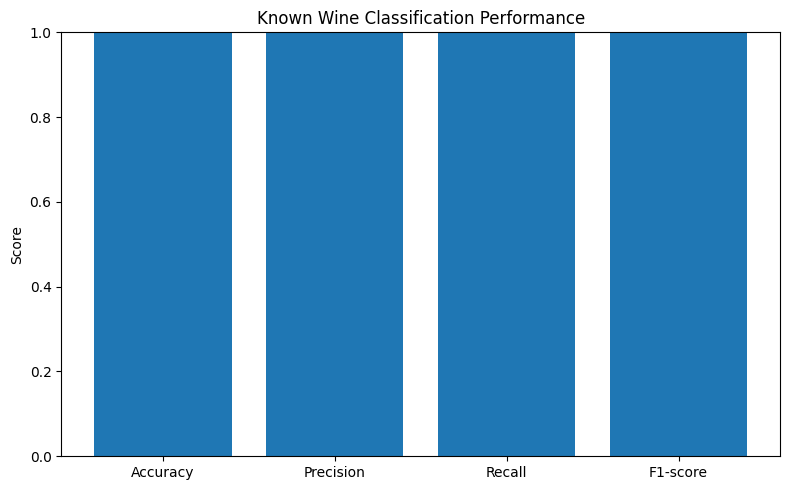

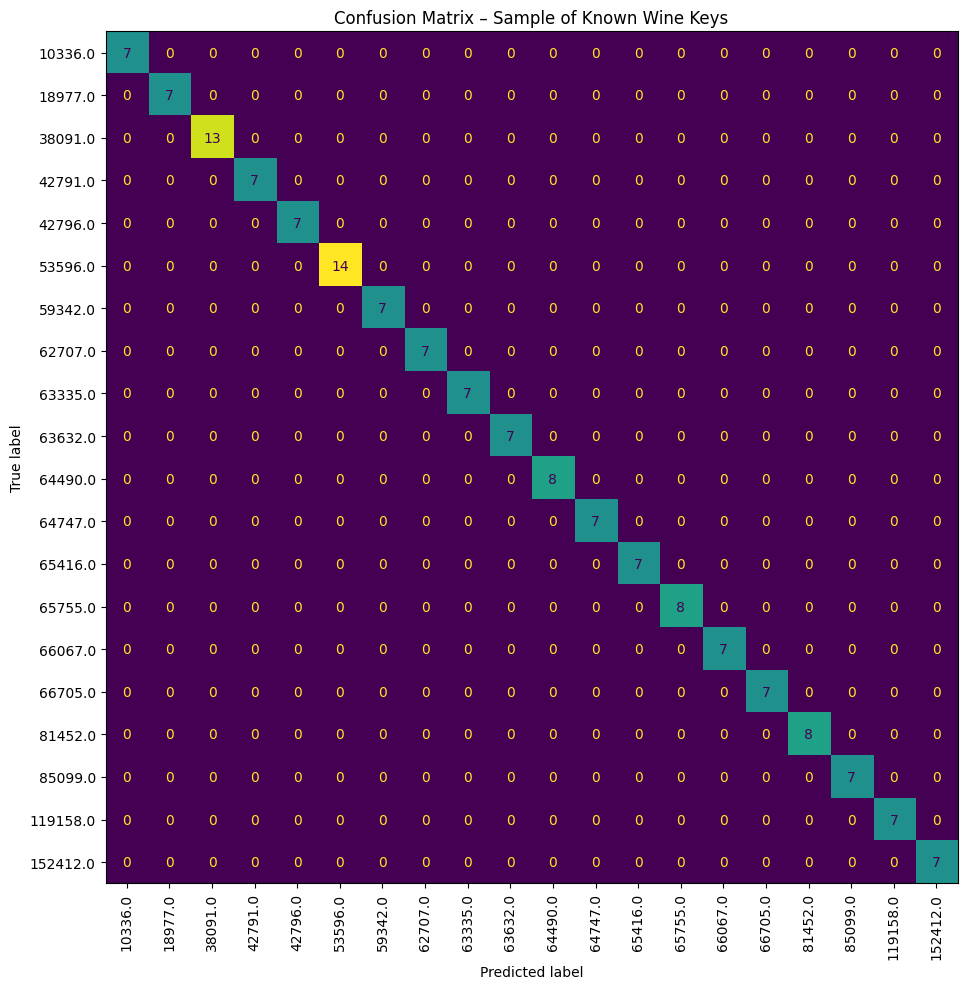

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(
    classification_metrics["Metric"],
    classification_metrics["Score"]
)

plt.ylim(0, 1)

plt.title(
    "Known Wine Classification Performance"
)

plt.ylabel("Score")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/classification_metrics.png",
    dpi=300
)

plt.show()


# Confusion matrix for first 20 encoded classes
selected_labels = np.arange(
    min(20, len(label_encoder.classes_))
)

cm = confusion_matrix(
    y_known_test,
    known_predictions,
    labels=selected_labels
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        str(label_encoder.classes_[i])[:15]
        for i in selected_labels
    ]
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap=None,
    colorbar=False
)

plt.title(
    "Confusion Matrix – Sample of Known Wine Keys"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#**OPEN-SET RECOGNITION**

##**Determine OSR threshold from known validation confidence**

In [18]:
# Split training embeddings again to create
# threshold-calibration data

X_osr_train, X_osr_val, y_osr_train, y_osr_val = (
    train_test_split(
        X_train,
        y_train,
        test_size=0.20,
        random_state=SEED,
        stratify=y_train
    )
)


osr_classifier = LogisticRegression(
    max_iter=1500,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)


osr_classifier.fit(
    X_osr_train,
    y_osr_train
)


val_probabilities = (
    osr_classifier.predict_proba(
        X_osr_val
    )
)

val_confidence = (
    val_probabilities.max(axis=1)
)


OSR_THRESHOLD = float(
    np.percentile(
        val_confidence,
        OSR_PERCENTILE
    )
)


print(
    f"OSR confidence threshold: "
    f"{OSR_THRESHOLD:.4f}"
)


osr_config = {
    "method":
        "Maximum Softmax Probability rejection",
    "threshold":
        OSR_THRESHOLD,
    "calibration_percentile":
        OSR_PERCENTILE
}


joblib.dump(
    osr_config,
    f"{OUTPUT_DIR}/models/osr_config.pkl"
)


with open(
    f"{OUTPUT_DIR}/results/osr_config.json",
    "w"
) as f:

    json.dump(
        osr_config,
        f,
        indent=4
    )

OSR confidence threshold: 0.1834


#**Test OSR on known + held-out unknown Wine Keys**

In [19]:
known_osr_probs = classifier.predict_proba(
    X_known_test
)

unknown_osr_probs = classifier.predict_proba(
    X_heldout
)


known_conf = known_osr_probs.max(axis=1)
unknown_conf = unknown_osr_probs.max(axis=1)


known_rejected = (
    known_conf < OSR_THRESHOLD
)

unknown_rejected = (
    unknown_conf < OSR_THRESHOLD
)


# 0 = known
# 1 = unknown

y_osr_true = np.concatenate([
    np.zeros(len(known_conf)),
    np.ones(len(unknown_conf))
])


# Lower confidence = more likely unknown
unknown_score = np.concatenate([
    1 - known_conf,
    1 - unknown_conf
])


y_osr_pred = np.concatenate([
    known_rejected.astype(int),
    unknown_rejected.astype(int)
])


osr_accuracy = accuracy_score(
    y_osr_true,
    y_osr_pred
)

osr_precision, osr_recall, osr_f1, _ = (
    precision_recall_fscore_support(
        y_osr_true,
        y_osr_pred,
        average="binary",
        zero_division=0
    )
)


try:
    osr_auc = roc_auc_score(
        y_osr_true,
        unknown_score
    )
except:
    osr_auc = np.nan


osr_metrics = pd.DataFrame({
    "Metric": [
        "OSR Accuracy",
        "Unknown Precision",
        "Unknown Recall",
        "Unknown F1",
        "AUROC",
        "Known Rejection Rate",
        "Unknown Detection Rate"
    ],

    "Score": [
        osr_accuracy,
        osr_precision,
        osr_recall,
        osr_f1,
        osr_auc,
        known_rejected.mean(),
        unknown_rejected.mean()
    ]
})


display(osr_metrics)


osr_metrics.to_csv(
    f"{OUTPUT_DIR}/results/osr_metrics.csv",
    index=False
)

,Metric,Score
0,OSR Accuracy,0.947721
1,Unknown Precision,0.965665
2,Unknown Recall,0.925926
3,Unknown F1,0.945378
4,AUROC,0.990495
5,Known Rejection Rate,0.031455
6,Unknown Detection Rate,0.925926


#**OSR visualizations**

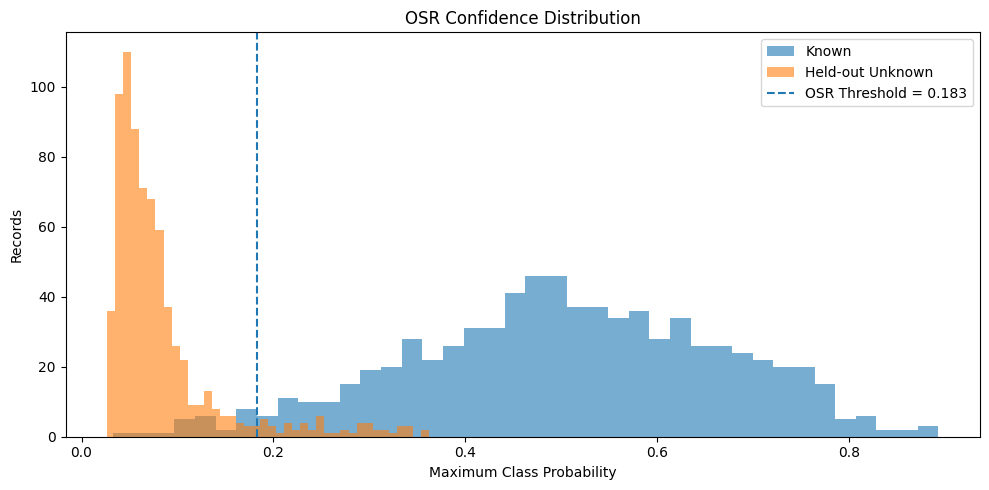

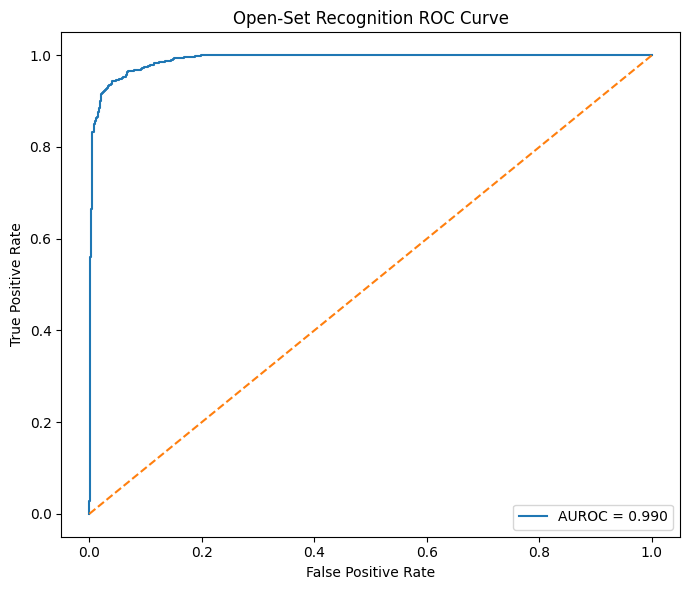

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    known_conf,
    bins=40,
    alpha=0.6,
    label="Known"
)

plt.hist(
    unknown_conf,
    bins=40,
    alpha=0.6,
    label="Held-out Unknown"
)

plt.axvline(
    OSR_THRESHOLD,
    linestyle="--",
    label=f"OSR Threshold = {OSR_THRESHOLD:.3f}"
)

plt.xlabel("Maximum Class Probability")
plt.ylabel("Records")

plt.title(
    "OSR Confidence Distribution"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/osr_confidence_distribution.png",
    dpi=300
)

plt.show()


fpr, tpr, _ = roc_curve(
    y_osr_true,
    unknown_score
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUROC = {osr_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Open-Set Recognition ROC Curve"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/osr_roc_curve.png",
    dpi=300
)

plt.show()

#**EXTERNAL UNKNOWN DATA**

In [21]:
external_unknown_df = None
X_external_unknown = None


if unknown_df is not None:

    unknown_target = find_column(
        unknown_df.columns,
        [
            "winekey",
            "wine_key",
            "wineid",
            "wine_id"
        ]
    )

    unknown_original = find_column(
        unknown_df.columns,
        [
            "origin_name",
            "originalname",
            "original_name",
            "wine_name",
            "name"
        ]
    )

    unknown_standard = find_column(
        unknown_df.columns,
        [
            "std_name",
            "standardname",
            "standard_name"
        ]
    )


    if unknown_original and unknown_standard:

        unknown_df["text"] = (
            unknown_df[unknown_original]
            .fillna("")
            .astype(str)
            + " "
            + unknown_df[unknown_standard]
            .fillna("")
            .astype(str)
        )

    elif unknown_original:

        unknown_df["text"] = (
            unknown_df[unknown_original]
            .fillna("")
            .astype(str)
        )

    elif unknown_standard:

        unknown_df["text"] = (
            unknown_df[unknown_standard]
            .fillna("")
            .astype(str)
        )

    else:

        raise ValueError(
            "Unknown dataset has no usable text column."
        )


    unknown_df["text"] = (
        unknown_df["text"]
        .apply(clean_text)
    )


    unknown_df = unknown_df[
        unknown_df["text"].str.len() > 2
    ].copy()


    # Prevent Wine Key leakage if target exists
    if unknown_target:

        unknown_df = unknown_df[
            ~unknown_df[unknown_target]
            .isin(known_classes)
        ].copy()


    n_external = min(
        MAX_EXTERNAL_UNKNOWN,
        len(unknown_df)
    )


    external_unknown_df = (
        unknown_df.sample(
            n=n_external,
            random_state=SEED
        )
        .reset_index(drop=True)
    )


    print(
        "External unknown sample:",
        len(external_unknown_df)
    )


    X_external_unknown = (
        generate_embeddings(
            external_unknown_df["text"]
        )
    )


    external_probs = (
        classifier.predict_proba(
            X_external_unknown
        )
    )


    external_unknown_df[
        "predicted_known_class"
    ] = label_encoder.inverse_transform(
        external_probs.argmax(axis=1)
    )


    external_unknown_df[
        "known_class_confidence"
    ] = external_probs.max(axis=1)


    external_unknown_df[
        "osr_decision"
    ] = np.where(
        external_unknown_df[
            "known_class_confidence"
        ] < OSR_THRESHOLD,
        "UNKNOWN",
        "KNOWN"
    )


    external_unknown_df.to_csv(
        f"{OUTPUT_DIR}/processed_data/"
        "external_unknown_predictions.csv",
        index=False
    )


    print(
        external_unknown_df[
            "osr_decision"
        ].value_counts()
    )

else:

    print(
        "No external unknown dataset available."
    )

External unknown sample: 5000


Batches:   0%|          | 0/40 [00:00<?, ?it/s]

osr_decision
UNKNOWN    4925
KNOWN        75
Name: count, dtype: int64


#**SEMANTIC CLUSTERING**

##**Build rejected unknown pool and cluster it**

In [22]:
# Held-out records rejected by OSR

rejected_mask = (
    unknown_conf < OSR_THRESHOLD
)


rejected_df = (
    heldout_df
    .iloc[
        np.where(rejected_mask)[0]
    ]
    .copy()
    .reset_index(drop=True)
)


rejected_embeddings = (
    X_heldout[rejected_mask]
)


print(
    "Held-out records rejected as unknown:",
    len(rejected_df)
)


# Add external rejected records
if (
    external_unknown_df is not None
    and X_external_unknown is not None
):

    external_mask = (
        external_unknown_df[
            "osr_decision"
        ].values == "UNKNOWN"
    )


    ext_rejected_df = (
        external_unknown_df[
            external_mask
        ]
        .copy()
        .reset_index(drop=True)
    )


    ext_embeddings = (
        X_external_unknown[
            external_mask
        ]
    )


    # Keep common columns
    ext_rejected_df[
        "source"
    ] = "external_unknown"

    rejected_df[
        "source"
    ] = "heldout_unknown"


    # Clustering dataframe only needs text/source
    cluster_a = rejected_df[
        ["text", "source"]
    ].copy()

    cluster_a[
        "true_wine_key"
    ] = rejected_df[
        TARGET_COL
    ].astype(str).values


    cluster_b = ext_rejected_df[
        ["text", "source"]
    ].copy()

    cluster_b[
        "true_wine_key"
    ] = "EXTERNAL_UNKNOWN"


    clustering_df = pd.concat(
        [cluster_a, cluster_b],
        ignore_index=True
    )


    clustering_embeddings = np.vstack([
        rejected_embeddings,
        ext_embeddings
    ])

else:

    clustering_df = rejected_df[
        ["text", TARGET_COL]
    ].copy()

    clustering_df.rename(
        columns={
            TARGET_COL: "true_wine_key"
        },
        inplace=True
    )

    clustering_df[
        "source"
    ] = "heldout_unknown"

    clustering_embeddings = (
        rejected_embeddings
    )


# Limit clustering workload
if len(clustering_df) > MAX_CLUSTER_RECORDS:

    sampled_indices = (
        clustering_df.sample(
            n=MAX_CLUSTER_RECORDS,
            random_state=SEED
        ).index
    )

    clustering_df = (
        clustering_df
        .loc[sampled_indices]
        .reset_index(drop=True)
    )

    clustering_embeddings = (
        clustering_embeddings[
            sampled_indices
        ]
    )


print(
    "Records used for semantic clustering:",
    len(clustering_df)
)


actual_clusters = min(
    N_CLUSTERS,
    max(
        2,
        len(clustering_df) // 20
    )
)


cluster_model = MiniBatchKMeans(
    n_clusters=actual_clusters,
    random_state=SEED,
    batch_size=256,
    n_init=10
)


cluster_labels = (
    cluster_model.fit_predict(
        clustering_embeddings
    )
)


clustering_df[
    "cluster"
] = cluster_labels


joblib.dump(
    cluster_model,
    f"{OUTPUT_DIR}/models/"
    "semantic_clustering_model.pkl"
)


clustering_df.to_csv(
    f"{OUTPUT_DIR}/processed_data/"
    "clustered_unknown_records.csv",
    index=False
)


print("\nCluster distribution:")

display(
    clustering_df[
        "cluster"
    ].value_counts()
    .sort_index()
    .to_frame("Records")
)

Held-out records rejected as unknown: 675
Records used for semantic clustering: 5000

Cluster distribution:


,Records
cluster,
0,203
1,407
2,126
3,201
4,290
5,393
6,657
7,215
8,453


##**Evaluate and visualize semantic clusters**

,Metric,Score
0,Number of Clusters,20.000000
1,Records Clustered,5000.000000
2,Silhouette Score,0.032136


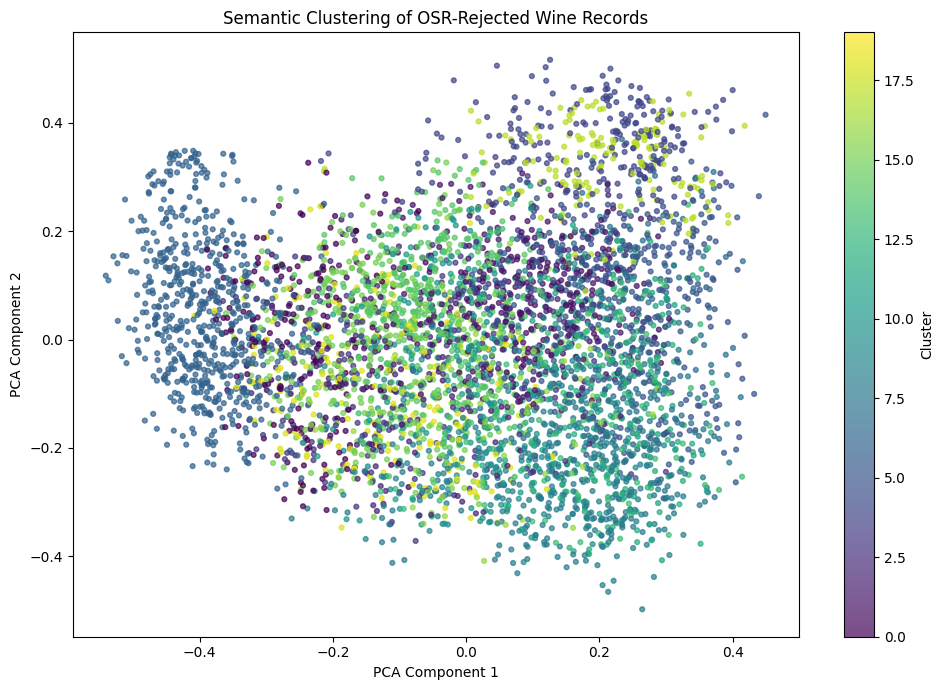

In [23]:
if (
    len(clustering_df) > actual_clusters
    and actual_clusters > 1
):

    silhouette = silhouette_score(
        clustering_embeddings,
        cluster_labels,
        sample_size=min(
            2000,
            len(clustering_df)
        ),
        random_state=SEED
    )

else:

    silhouette = np.nan


cluster_metrics = pd.DataFrame({
    "Metric": [
        "Number of Clusters",
        "Records Clustered",
        "Silhouette Score"
    ],

    "Score": [
        actual_clusters,
        len(clustering_df),
        silhouette
    ]
})


display(cluster_metrics)


cluster_metrics.to_csv(
    f"{OUTPUT_DIR}/results/"
    "clustering_metrics.csv",
    index=False
)


# PCA is used only for 2-D visualization,
# not as the clustering representation.

pca = PCA(
    n_components=2,
    random_state=SEED
)

cluster_2d = pca.fit_transform(
    clustering_embeddings
)


plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    cluster_2d[:, 0],
    cluster_2d[:, 1],
    c=cluster_labels,
    s=12,
    alpha=0.7
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title(
    "Semantic Clustering of OSR-Rejected Wine Records"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/"
    "semantic_clusters.png",
    dpi=300
)

plt.show()

#**HUMAN-IN-THE-LOOP**

##**Generate HITL review file**

In [24]:
HITL_PER_CLUSTER = 10


hitl_samples = []


for cluster_id in sorted(
    clustering_df["cluster"].unique()
):

    group = clustering_df[
        clustering_df["cluster"] == cluster_id
    ]


    sample = group.sample(
        n=min(
            HITL_PER_CLUSTER,
            len(group)
        ),
        random_state=SEED
    ).copy()


    sample[
        "suggested_cluster_label"
    ] = f"UNKNOWN_CLUSTER_{cluster_id}"


    sample[
        "human_verified_label"
    ] = ""


    sample[
        "verification_status"
    ] = "PENDING"


    hitl_samples.append(sample)


hitl_review = pd.concat(
    hitl_samples,
    ignore_index=True
)


hitl_review.to_csv(
    f"{OUTPUT_DIR}/results/"
    "HITL_review_required.csv",
    index=False
)


print(
    "HITL review records:",
    len(hitl_review)
)

print(
    "\nIMPORTANT: human_verified_label must "
    "be completed by a human reviewer."
)


display(
    hitl_review.head(20)
)

HITL review records: 191

IMPORTANT: human_verified_label must be completed by a human reviewer.


,text,source,true_wine_key,cluster,suggested_cluster_label,human_verified_label,verification_status
0,two hands wines two hands picture series - the...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
1,2006 giant steps winery yarra valley sexton vi...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
2,plantaganet riesling wa white wine plantagenet...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
3,yering station chardonnay 2008 chardonnay whit...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
4,hardys zero alcohol free chardonnay accolade w...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
5,lot 1008 b175 2 bottles woop woop wines south ...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
6,2011 chardonnay charles sturt range orange cha...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
7,the eleven chardonnay montalto vineyard port p...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
8,tyrrell's wine old winery verdelho tyrrells ol...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING
9,1990 arthur's creek estate chardonnay a white ...,external_unknown,EXTERNAL_UNKNOWN,0,UNKNOWN_CLUSTER_0,,PENDING


#**EXPERIMENTAL HITL SIMULATION FOR RETRAINING**

In [25]:
# ----------------------------------------------------
# Experimental HITL simulation
# ----------------------------------------------------
# We use ONLY held-out records whose true Wine Key is
# available in matched_wines.csv.
#
# This simulates a human successfully assigning the
# correct label after OSR + clustering.
# ----------------------------------------------------


verified_mask = (
    rejected_df["source"]
    == "heldout_unknown"
)


verified_df = (
    rejected_df[
        verified_mask
    ]
    .copy()
)


print(
    "Available verified held-out records:",
    len(verified_df)
)


# Select limited labelled samples per new class
retraining_samples = []


for wine_key, group in verified_df.groupby(
    TARGET_COL
):

    if len(group) >= 5:

        retraining_samples.append(
            group.sample(
                n=min(20, len(group)),
                random_state=SEED
            )
        )


if len(retraining_samples) == 0:

    raise ValueError(
        "Not enough OSR-rejected held-out "
        "records for retraining."
    )


retraining_df = pd.concat(
    retraining_samples,
    ignore_index=True
)


print(
    "Records selected for experimental retraining:",
    len(retraining_df)
)

print(
    "New Wine Keys introduced:",
    retraining_df[TARGET_COL].nunique()
)


# Split newly labelled data
new_train_df, new_test_df = train_test_split(
    retraining_df,
    test_size=0.30,
    random_state=SEED,
    stratify=retraining_df[TARGET_COL]
)


print(
    "New-label training:",
    len(new_train_df)
)

print(
    "New-label evaluation:",
    len(new_test_df)
)


# Generate embeddings
X_new_train = generate_embeddings(
    new_train_df["text"]
)

X_new_test = generate_embeddings(
    new_test_df["text"]
)


# Original training + verified labels
combined_train_df = pd.concat(
    [
        train_df[["text", TARGET_COL]],
        new_train_df[["text", TARGET_COL]]
    ],
    ignore_index=True
)


X_combined = np.vstack([
    X_train,
    X_new_train
])


retrain_encoder = LabelEncoder()

y_combined = (
    retrain_encoder.fit_transform(
        combined_train_df[TARGET_COL]
    )
)


retrained_classifier = LogisticRegression(
    max_iter=1500,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)


print("\nRetraining classifier...")

retrained_classifier.fit(
    X_combined,
    y_combined
)


joblib.dump(
    retrained_classifier,
    f"{OUTPUT_DIR}/models/"
    "retrained_wine_classifier.pkl"
)

joblib.dump(
    retrain_encoder,
    f"{OUTPUT_DIR}/models/"
    "retrained_label_encoder.pkl"
)


print("Retrained model saved.")

Available verified held-out records: 675
Records selected for experimental retraining: 385
New Wine Keys introduced: 20
New-label training: 269
New-label evaluation: 116


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining classifier...
Retrained model saved.


#**BEFORE/AFTER COMPARISON**

##**Evaluating retraining and generate final visualizations**

,Measure,Score
0,Original known-class accuracy,0.997379
1,Unknown detection before retraining,1.000000
2,New-class accuracy after retraining,1.000000
3,New-class precision after retraining,1.000000
4,New-class recall after retraining,1.000000
5,New-class F1 after retraining,1.000000
6,Original known accuracy after retraining,0.997379


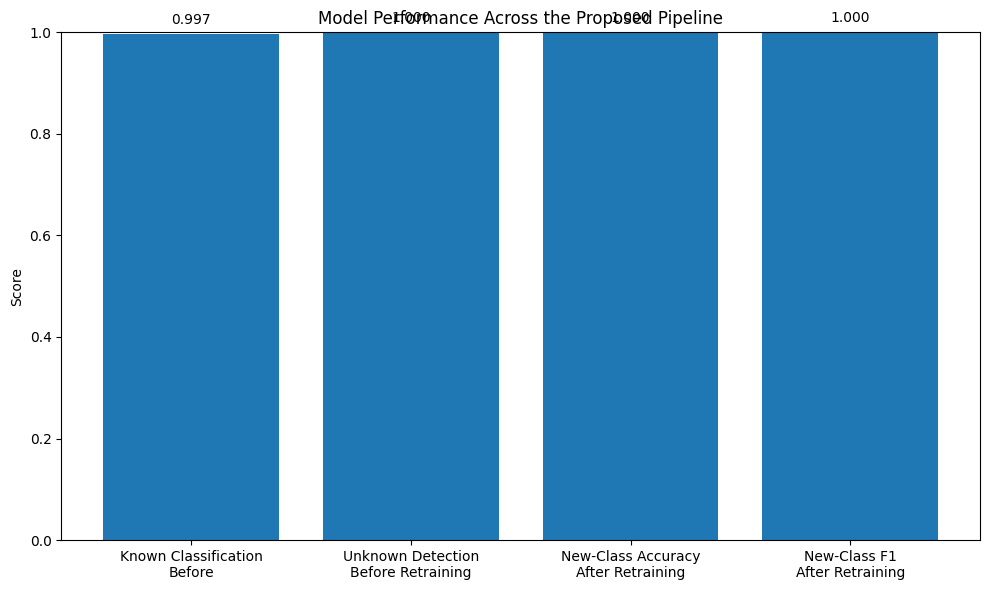


FINAL PROJECT SUMMARY
full_clean_dataset_records: 482684
full_unique_wine_keys: 12842
known_classes: 100
heldout_unknown_classes: 20
training_records: 3052
known_test_records: 763
heldout_unknown_records: 729
classification_accuracy: 0.9974
classification_precision: 0.9977
classification_recall: 0.9974
classification_f1: 0.9974
osr_threshold: 0.1834
osr_accuracy: 0.9477
osr_unknown_precision: 0.9657
osr_unknown_recall: 0.9259
osr_unknown_f1: 0.9454
osr_auroc: 0.9905
unknown_detection_rate: 0.9259
records_semantically_clustered: 5000
semantic_clusters: 20
silhouette_score: 0.0321
hitl_review_records: 191
experimental_retraining_records: 269
new_class_accuracy_after_retraining: 1.0000
new_class_f1_after_retraining: 1.0000
known_accuracy_after_retraining: 0.9974


In [26]:
# ---------------------------------------------------
# Evaluate new classes BEFORE retraining
# ---------------------------------------------------

before_probs = classifier.predict_proba(
    X_new_test
)

before_conf = before_probs.max(axis=1)

before_unknown_detected = (
    before_conf < OSR_THRESHOLD
).mean()


# ---------------------------------------------------
# Evaluate new classes AFTER retraining
# ---------------------------------------------------

y_new_test_retrained = (
    retrain_encoder.transform(
        new_test_df[TARGET_COL]
    )
)


after_predictions = (
    retrained_classifier.predict(
        X_new_test
    )
)


after_accuracy = accuracy_score(
    y_new_test_retrained,
    after_predictions
)


after_precision, after_recall, after_f1, _ = (
    precision_recall_fscore_support(
        y_new_test_retrained,
        after_predictions,
        average="weighted",
        zero_division=0
    )
)


# Evaluate original known test after retraining
known_test_retrained_y = (
    retrain_encoder.transform(
        known_test_df[TARGET_COL]
    )
)


known_after_pred = (
    retrained_classifier.predict(
        X_known_test
    )
)


known_after_accuracy = accuracy_score(
    known_test_retrained_y,
    known_after_pred
)


comparison = pd.DataFrame({
    "Measure": [
        "Original known-class accuracy",
        "Unknown detection before retraining",
        "New-class accuracy after retraining",
        "New-class precision after retraining",
        "New-class recall after retraining",
        "New-class F1 after retraining",
        "Original known accuracy after retraining"
    ],

    "Score": [
        accuracy,
        before_unknown_detected,
        after_accuracy,
        after_precision,
        after_recall,
        after_f1,
        known_after_accuracy
    ]
})


display(comparison)


comparison.to_csv(
    f"{OUTPUT_DIR}/results/"
    "retraining_comparison.csv",
    index=False
)


# ------------------------------
# Visualization
# ------------------------------

plot_df = pd.DataFrame({
    "Stage": [
        "Known Classification\nBefore",
        "Unknown Detection\nBefore Retraining",
        "New-Class Accuracy\nAfter Retraining",
        "New-Class F1\nAfter Retraining"
    ],

    "Score": [
        accuracy,
        before_unknown_detected,
        after_accuracy,
        after_f1
    ]
})


plt.figure(figsize=(10, 6))

bars = plt.bar(
    plot_df["Stage"],
    plot_df["Score"]
)

plt.ylim(0, 1)

plt.ylabel("Score")

plt.title(
    "Model Performance Across the Proposed Pipeline"
)


for bar, value in zip(
    bars,
    plot_df["Score"]
):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figures/"
    "retraining_performance_comparison.png",
    dpi=300
)

plt.show()


# -----------------------------------
# Final project summary
# -----------------------------------

final_summary = {

    "full_clean_dataset_records":
        int(len(matched_df)),

    "full_unique_wine_keys":
        int(matched_df[TARGET_COL].nunique()),

    "known_classes":
        int(len(known_classes)),

    "heldout_unknown_classes":
        int(len(heldout_classes)),

    "training_records":
        int(len(train_df)),

    "known_test_records":
        int(len(known_test_df)),

    "heldout_unknown_records":
        int(len(heldout_df)),

    "classification_accuracy":
        float(accuracy),

    "classification_precision":
        float(precision),

    "classification_recall":
        float(recall),

    "classification_f1":
        float(f1),

    "osr_threshold":
        float(OSR_THRESHOLD),

    "osr_accuracy":
        float(osr_accuracy),

    "osr_unknown_precision":
        float(osr_precision),

    "osr_unknown_recall":
        float(osr_recall),

    "osr_unknown_f1":
        float(osr_f1),

    "osr_auroc":
        float(osr_auc),

    "unknown_detection_rate":
        float(unknown_rejected.mean()),

    "records_semantically_clustered":
        int(len(clustering_df)),

    "semantic_clusters":
        int(actual_clusters),

    "silhouette_score":
        float(silhouette),

    "hitl_review_records":
        int(len(hitl_review)),

    "experimental_retraining_records":
        int(len(new_train_df)),

    "new_class_accuracy_after_retraining":
        float(after_accuracy),

    "new_class_f1_after_retraining":
        float(after_f1),

    "known_accuracy_after_retraining":
        float(known_after_accuracy)
}


with open(
    f"{OUTPUT_DIR}/results/"
    "final_summary.json",
    "w"
) as f:

    json.dump(
        final_summary,
        f,
        indent=4
    )


print("\nFINAL PROJECT SUMMARY")

for key, value in final_summary.items():

    if isinstance(value, float):
        print(
            f"{key}: {value:.4f}"
        )

    else:
        print(
            f"{key}: {value}"
        )

#**Export ALL results/models/figures into ONE ZIP**

In [27]:
# =====================================================
# FINAL EXPORT
# =====================================================

from google.colab import files
import os
import zipfile


FINAL_ZIP = (
    "/content/Wine_Classification_"
    "Complete_Results.zip"
)


# Create manifest before ZIP
manifest = []


for root, dirs, filenames in os.walk(
    OUTPUT_DIR
):

    for filename in filenames:

        full_path = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            full_path,
            OUTPUT_DIR
        )

        manifest.append({
            "file": relative_path,
            "size_mb": round(
                os.path.getsize(full_path)
                / (1024 ** 2),
                4
            )
        })


manifest_df = pd.DataFrame(
    manifest
)


manifest_df.to_csv(
    f"{OUTPUT_DIR}/FILE_MANIFEST.csv",
    index=False
)


# Create ZIP
with zipfile.ZipFile(
    FINAL_ZIP,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, filenames in os.walk(
        OUTPUT_DIR
    ):

        for filename in filenames:

            full_path = os.path.join(
                root,
                filename
            )

            relative_path = os.path.relpath(
                full_path,
                OUTPUT_DIR
            )

            zipf.write(
                full_path,
                arcname=relative_path
            )


print("=" * 60)
print("PROJECT EXPORT COMPLETE")
print("=" * 60)

print(
    "\nZIP:",
    FINAL_ZIP
)

print(
    "ZIP size:",
    round(
        os.path.getsize(FINAL_ZIP)
        / (1024 ** 2),
        2
    ),
    "MB"
)


print("\nFiles included:")

display(
    manifest_df.sort_values(
        "file"
    ).reset_index(drop=True)
)


print(
    "\nPKL files included:"
)

pkl_files = manifest_df[
    manifest_df["file"]
    .str.endswith(".pkl")
]

display(pkl_files)


print(
    "\nDownloading final ZIP..."
)

files.download(
    FINAL_ZIP
)

PROJECT EXPORT COMPLETE

ZIP: /content/Wine_Classification_Complete_Results.zip
ZIP size: 10.57 MB

Files included:


,file,size_mb
0,experiment_config.json,0.0003
1,figures/classification_metrics.png,0.0641
2,figures/confusion_matrix.png,0.3042
3,figures/osr_confidence_distribution.png,0.0959
4,figures/osr_roc_curve.png,0.1141
5,figures/retraining_performance_comparison.png,0.1028
6,figures/semantic_clusters.png,2.5108
7,figures/text_length_distribution.png,0.0729
8,figures/top_wine_keys.png,0.1837
9,models/label_encoder.pkl,0.0011



PKL files included:


,file,size_mb
23,models/wine_classifier.pkl,0.2953
24,models/retrained_wine_classifier.pkl,0.3542
25,models/retrained_label_encoder.pkl,0.0012
26,models/semantic_clustering_model.pkl,0.0494
27,models/osr_config.pkl,0.0001
28,models/label_encoder.pkl,0.0011


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>